# 05 · Model contracts on historical stock observations

**Objective:** carry the reconciled option/stock/cash accounting into two dated stock-price windows, using synthetic European model contracts and strictly earlier volatility calibration.

The underlying observations are audited FMP split-adjusted closes for JPM, PNC and GS. **The option premiums are model prices, not historical option quotes.** Historical stock paths are observed outcomes, not Q simulations. The study does not claim an executable listed-option backtest.

The fixed cases are short model calls with a five-session stock hedge, a long-equity benchmark, and the same equities with purchased model puts. Protective puts are **not automatically delta-neutralized**. The two equity cases use identical shares and initial capital.

This notebook runs independently from a fresh kernel after the audited underlying-price CSV exists. It reads cached prices only; it never reads or prints FMP credentials. The separate command-line runner writes permanent CSV/JSON/report artifacts.

## 1 · Load the accounting implementation and audited prices

The source is `data/market/prices_split_adjusted.csv`, accompanied by source-field, adjustment and hash metadata. The price table contains observed stock prices; the option positions and rules remain explicit model assumptions.

In [1]:
from pathlib import Path
from hashlib import sha256
import sys
import json
import pandas as pd
import matplotlib
matplotlib.use("module://matplotlib_inline.backend_inline")
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / "hedging_harness" / "replay.py").is_file():
    ROOT = ROOT.parent
assert (ROOT / "hedging_harness" / "replay.py").is_file(), f"Wrong project root: {ROOT}"
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from scripts.run_model_contract_replay import run_study, plot_study

PRICES_PATH = ROOT / "data/market/prices_split_adjusted.csv"
CALIBRATION_RETURNS = 252
NOTIONAL_PER_NAME = 100000.0
RATE = 0.04
COST_BPS = 5.0
HEDGE_EVERY = 5

history = pd.read_csv(PRICES_PATH, index_col="date", parse_dates=["date"])
source_metadata = json.loads((PRICES_PATH.parent / "prices_metadata.json").read_text())
print(f"Underlying history: {len(history):,} sessions; {history.index[0].date()} to {history.index[-1].date()}")
print(f"Price basis: {source_metadata['adjustment']}; dividend cashflows included: {source_metadata['dividend_cashflows_included']}")
display(history.head())

Underlying history: 4,236 sessions; 2010-01-04 to 2026-11-04
Price basis: split_adjusted; dividend cashflows included: False


,JPM,PNC,GS
date,,,
2010-01-04,42.85,53.51,173.08
2010-01-05,43.68,54.05,176.14
2010-01-06,43.92,54.05,174.26
2010-01-07,44.79,56.98,177.67
2010-01-08,44.68,57.13,174.31


## 2 · Freeze model inputs using prior data only

The predefined windows are 2019-01-02 through 2019-03-29 and 2020-02-03 through 2020-04-30. For each window, estimate fixed volatility from **252 log returns requiring 253 closing prices strictly before inception**, annualized by `sqrt(252)`.

This historical realized-volatility proxy is used as model sigma. It is not a historical implied volatility, and the constant 4% financing rate is an illustrative assumption rather than a historical rate series.

Each option strikes at its underlying's inception close and expires at the window's last declared session. Quantities correspond to $100,000 underlying notional per name. The equity comparisons share $300,000 initial capital. The short-option liability account starts at zero capital and has dollar P&L rather than a comparable equity investment return.

In [2]:
study = run_study(
    PRICES_PATH, calibration_returns=CALIBRATION_RETURNS,
    notional_per_name=NOTIONAL_PER_NAME, rate=RATE, cost_bps=COST_BPS,
    hedge_every=HEDGE_EVERY, write_outputs=False, make_plot=False,
)
assert study["manifest"]["market_data_source_verified"]
calibration = study["calibration"]
assert (pd.to_datetime(calibration["cutoff"]) < pd.to_datetime(calibration["replay_start"])).all()
assert calibration["return_observations"].eq(CALIBRATION_RETURNS).all()
display(calibration)

cutoff first_observation replay_start  \
window            name                                              
normal_2019       JPM   2018-12-31        2017-12-28   2019-01-02   
                  PNC   2018-12-31        2017-12-28   2019-01-02   
                  GS    2018-12-31        2017-12-28   2019-01-02   
stress_covid_2020 JPM   2020-01-31        2019-01-31   2020-02-03   
                  PNC   2020-01-31        2019-01-31   2020-02-03   
                  GS    2020-01-31        2019-01-31   2020-02-03   

                        price_observations  return_observations  \
window            name                                            
normal_2019       JPM                  253                  252   
                  PNC                  253                  252   
                  GS                   253                  252   
stress_covid_2020 JPM                  253                  252   
                  PNC                  253                  252   
                  GS                   253                  252   

                        annual_volatility  
window            name                     
normal_2019       JPM            0.220558  
                  PNC            0.232043  
                  GS             0.257866  
stress_covid_2020 JPM            0.189803  
                  PNC            0.199549  
                  GS             0.216205

## 3 · Inspect the account outcomes

Stock execution is assumed at the observed close plus the stated proportional fee. Options are model-priced at inception and cash-settle at expiry. Core equity and option hedge shares are separate sleeves, with stock execution netted by underlying.

`terminal_model_pnl` includes entry premiums, interest, stock trades, stock costs and settlement. `max_drawdown_dollars` describes the single observed model-account NAV history; it is not a Monte Carlo expected shortfall estimate. `peak_borrowing` measures observed funding requirements rather than margin adequacy.

The short-call liability and the long-equity portfolio have different mandates and capital baselines. Compare the equity and protective-put cases directly; use the short-call case to inspect replication/accounting behavior.

In [3]:
summary = study["summary"]
display(summary[[
    "observations", "initial_capital", "terminal_nav", "terminal_model_pnl",
    "max_drawdown_dollars", "stock_cost", "peak_borrowing"
]].round(4))

observations  initial_capital  \
window            strategy                                                  
normal_2019       short_calls_stock_hedged            61              0.0   
                  unhedged_equity                     61         300000.0   
                  protective_puts                     61         300000.0   
stress_covid_2020 short_calls_stock_hedged            62              0.0   
                  unhedged_equity                     62         300000.0   
                  protective_puts                     62         300000.0   

                                            terminal_nav  terminal_model_pnl  \
window            strategy                                                     
normal_2019       short_calls_stock_hedged      380.1648            380.1648   
                  unhedged_equity            316466.6119          16466.6119   
                  protective_puts            303966.1487           3966.1487   
stress_covid_2020 short_calls_stock_hedged    -6429.1598          -6429.1598   
                  unhedged_equity            219612.5025         -80387.4975   
                  protective_puts            289202.5277         -10797.4723   

                                            max_drawdown_dollars  stock_cost  \
window            strategy                                                     
normal_2019       short_calls_stock_hedged             1903.2696    326.8263   
                  unhedged_equity                     27121.7097    308.3882   
                  protective_puts                     24931.3372    308.3882   
stress_covid_2020 short_calls_stock_hedged             7548.9063    183.4166   
                  unhedged_equity                    138568.2232    259.9369   
                  protective_puts                     17145.8065    259.9369   

                                            peak_borrowing  
window            strategy                                  
normal_2019       short_calls_stock_hedged     289835.2497  
                  unhedged_equity                 151.4354  
                  protective_puts               12651.8986  
stress_covid_2020 short_calls_stock_hedged     177076.6166  
                  unhedged_equity                 151.4594  
                  protective_puts               10687.5354

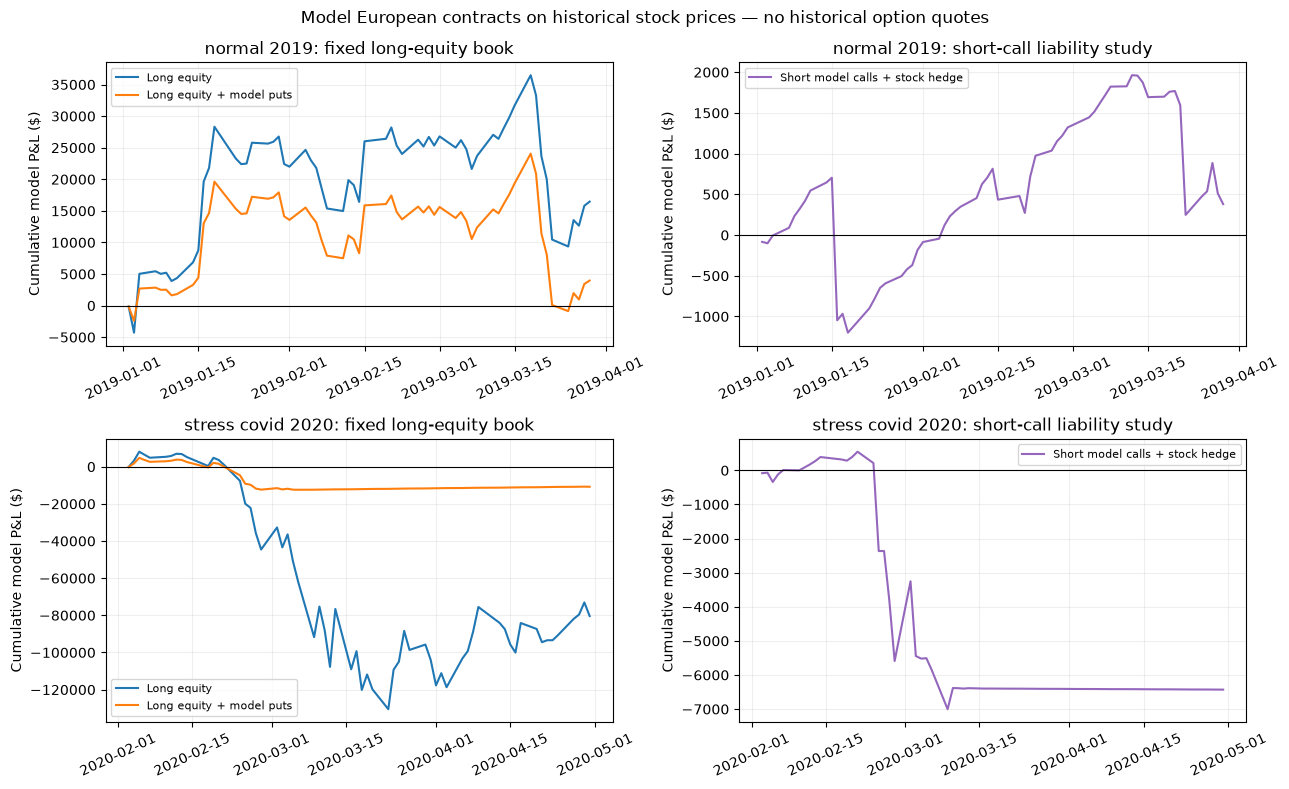

In [4]:
fig = plot_study(study)
plt.show()

## 4 · Reconcile representative dates

Every daily cash balance is independently reconstructed from the executed-stock trade records and instrument-level opening/settlement events. Final option payoffs are recomputed from observed terminal prices and signed quantities.

The representative rows below include inception, the first scheduled rebalance and expiry. Reconstruct each as:

**previous cash + interest + option entry + option settlement + core stock cash flow + hedge stock cash flow − stock cost = recorded cash.**

At inception, model-option cash flows are offset by signed option value in NAV. At expiry, the stock is liquidated and no option liability or asset remains. Receiving a written-option premium is not immediate profit, and a purchased put's premium is protection cost.

In [5]:
manual = study["manual_reconciliation"]
examples = manual.loc[
    (manual["window"].eq("normal_2019") & manual["strategy"].eq("short_calls_stock_hedged"))
    | (manual["window"].eq("stress_covid_2020") & manual["strategy"].eq("protective_puts"))
]
display(examples[[
    "window", "strategy", "date", "previous_cash", "interest", "option_entry_cashflow",
    "option_settlement_cashflow", "core_stock_cashflow", "hedge_stock_cashflow",
    "stock_cost", "recorded_cash", "residual"
]].round(6))
print("Stress-window put opening and settlement events:")
events = study["option_events"]
display(events.loc[
    events["window"].eq("stress_covid_2020") & events["strategy"].eq("protective_puts"),
    ["date", "instrument_id", "event", "spot", "signed_units", "opening_cashflow", "settlement_cashflow", "model_value"],
].round(6))

,window,strategy,date,previous_cash,interest,option_entry_cashflow,option_settlement_cashflow,core_stock_cashflow,hedge_stock_cashflow,stock_cost,recorded_cash,residual
0,normal_2019,short_calls_stock_hedged,2019-01-02,0.000000,0.000000,15225.556779,0.000000,0.000000,-166765.535721,83.382768,-151623.361710,0.0
1,normal_2019,short_calls_stock_hedged,2019-01-09,-151719.661079,-24.084397,0.000000,0.000000,0.000000,-17974.571063,8.987286,-169727.303825,0.0
2,normal_2019,short_calls_stock_hedged,2019-03-29,-209520.338808,-33.259836,0.000000,-16776.435469,0.000000,226823.610732,113.411805,380.164813,0.0
15,stress_covid_2020,protective_puts,2020-02-03,300000.000000,0.000000,-10434.552248,0.000000,-300000.000000,0.000000,150.000000,-10584.552248,0.0
16,stress_covid_2020,protective_puts,2020-02-10,-10591.274733,-1.681288,0.000000,0.000000,0.000000,0.000000,0.000000,-10592.956021,0.0
17,stress_covid_2020,protective_puts,2020-04-30,-10685.839061,-1.696300,0.000000,80126.101079,219873.898921,0.000000,109.936949,289202.527690,0.0


Stress-window put opening and settlement events:


/var/folders/fv/8kgvjzz53_s0kstrbq5d16vw0000gn/T/ipykernel_6882/2965591294.py:16: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].round(6))


,date,instrument_id,event,spot,signed_units,opening_cashflow,settlement_cashflow,model_value
18,2020-02-03,JPM_model_put,open,133.37,749.793807,-3244.243656,0.000000,3244.243656
19,2020-02-03,PNC_model_put,open,149.54,668.717400,-3433.427030,0.000000,3433.427030
20,2020-02-03,GS_model_put,open,239.01,418.392536,-3756.881563,0.000000,3756.881563
21,2020-04-30,JPM_model_put,settle,95.76,749.793807,0.000000,28199.745070,0.000000
22,2020-04-30,PNC_model_put,settle,106.67,668.717400,0.000000,28667.914939,0.000000
23,2020-04-30,GS_model_put,settle,183.42,418.392536,0.000000,23258.441069,0.000000


## 5 · Check causality, lifecycle and accounting

For each of the six runs, the audit checks cash aggregation, settlement payoff, final flat holdings and zero option value. A causality check modifies only later stock observations and confirms that earlier decisions and ledger rows remain identical. Volatility calibration uses a cutoff strictly before replay inception.

These checks establish the small **model-contract accounting replay**. They do not establish historical option quote coverage, American exercise handling, executable fills, unbiased sector membership, or generalization across many independent crises.

In [6]:
checks = study["checks"]
assert checks.drop(columns=["window", "strategy"]).all().all()
display(checks)
print("Model-contract accounting gate passed:", study["manifest"]["model_contract_accounting_gate_passed"])
print("Historical listed-option replay gate passed:", study["manifest"]["historical_option_backtest_gate_passed"])

,window,strategy,cash_from_trade_and_option_records,expiry_payoff_recomputed,terminal_shares_and_liabilities_zero,no_future_info_decisions,calibration_strictly_before_replay
0,normal_2019,short_calls_stock_hedged,True,True,True,True,True
1,normal_2019,unhedged_equity,True,True,True,True,True
2,normal_2019,protective_puts,True,True,True,True,True
3,stress_covid_2020,short_calls_stock_hedged,True,True,True,True,True
4,stress_covid_2020,unhedged_equity,True,True,True,True,True
5,stress_covid_2020,protective_puts,True,True,True,True,True


Model-contract accounting gate passed: True
Historical listed-option replay gate passed: False


## 6 · Record the exact study and export when needed

The in-memory manifest contains source/data hashes, prior-data cutoffs, each option position, the equity holdings, execution assumptions and full per-run provenance. The compact display omits repeated per-run detail; it remains available in `study['manifest']['runs']`.

For permanent CSV, plot and Markdown artifacts, run `.venv/bin/python scripts/run_model_contract_replay.py`. It writes a new `results/model-contract-replay-*` directory without overwriting previous results. No credentials are stored in its output.

In [7]:
record = {key: value for key, value in study["manifest"].items() if key != "runs"}
notebook_path = ROOT / "Hedging_Study_Notebooks/05_model_contract_replay.ipynb"
notebook_source = json.loads(notebook_path.read_text())
code_text = "\n\n".join(
    "".join(cell["source"]) for cell in notebook_source["cells"] if cell["cell_type"] == "code"
)
record["notebook_code_sha256"] = sha256(code_text.encode()).hexdigest()
print(json.dumps(record, indent=2))

{
  "study": "European model-contract accounting replay on historical stock prices",
  "generated_utc": "2026-11-06T01:46:17.903528+00:00",
  "model_options_are_historical_quoted_options": false,
  "historical_option_backtest_gate_passed": false,
  "model_contract_accounting_gate_passed": true,
  "prices_file": "/Users/saireddivari/MonteCarloEvaluations/data/market/prices_split_adjusted.csv",
  "prices_file_sha256": "fafef4fc0276fd7ed75ec808c6f8fa8822d41d35df4b938cf22b47d0fae31a27",
  "market_data_source_verified": true,
  "source_metadata_file": "/Users/saireddivari/MonteCarloEvaluations/data/market/prices_metadata.json",
  "price_basis": "FMP split-adjusted close; dividends excluded; not a total-return index",
  "historical_sigma_is_implied_volatility": false,
  "calibration_returns": 252,
  "windows": {
    "normal_2019": [
      "2019-01-02",
      "2019-03-29"
    ],
    "stress_covid_2020": [
      "2020-02-03",
      "2020-04-30"
    ]
  },
  "rate": 0.04,
  "rate_interpretation

## Research boundary

The underlying observations are real historical stock closes, and the fixed model volatility estimates use earlier observations only. The options themselves are synthetic fixed-volatility European cash-settled contracts. Dividends, option spreads, margin, borrow fees and corporate-action event processing remain outside the account.

This is the intermediate replay explicitly allowed when historical option quotes are unavailable. It demonstrates accounting and causal mechanics on a normal and a stress window. It does not replace market-option data, broad out-of-sample validation, forecast tests or 40–50-name generalization.